# Parte 1 — MDP + Q-Learning tabular (despacho de batería / BESS) con datos reales de XM

**Problema:** desplazamiento de demanda (*load shifting*), no especulación financiera.
La batería compra energía a la red cuando el precio de bolsa es bajo y cubre demanda
propia (costo evitado) cuando es alto, respetando las restricciones físicas del BESS.

Flujo del notebook:
1. Cargar el precio de bolsa nacional horario real (`PrecBolsNaci`) de XM con `pydataxm`.
   Cada descarga actualiza el respaldo `data/raw/xm_precio_bolsa.csv`; si la API falla se usa ese CSV.
2. Dividir los días en orden cronológico: 70 % entrenamiento, 15 % validación, 15 % prueba.
   El cuartil de precio de cada hora se calcula con una **ventana móvil causal** de las
   168 h anteriores, así el estado distingue horas baratas y caras aunque cambie el nivel
   de precios entre meses secos y húmedos.
3. Elegir `alpha` y el decaimiento de ε **solo con validación** (varias semillas).
4. Entrenar `QLearningAgent` 5,000 episodios con los hiperparámetros elegidos.
5. Calcular la política de referencia por **Iteración de Valores** sobre el modelo empírico de entrenamiento.
6. Reportar en **prueba** (días nunca usados para decidir nada) el ahorro de la Línea Base justa,
   Q-Learning e Iteración de Valores.

In [1]:
from __future__ import annotations
import sys
import time
from datetime import date
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.data.download_xm import obtener_serie_horaria
from src.part1_rl.environment import BatteryEnv, Accion, umbrales_moviles, VENTANA_CUARTILES_H
from src.part1_rl.agent import QLearningAgent
from src.part1_rl.value_iteration import value_iteration_policy

SEMILLA = 42
EPISODIOS = 5000
FRACCION_TRAIN, FRACCION_VAL = 0.70, 0.15  # el 15 % restante es prueba
# Periodo fijo (365 días) para que los resultados sean reproducibles.
USAR_XM = True
FECHA_INICIO, FECHA_FIN = date(2025, 11, 10), date(2026, 11, 9)
# Con 1 kWh por escalón (batería de 4 kWh) la recompensa es exactamente ±precio (COP/kWh).
ENERGIA_POR_NIVEL_KWH = 1.0
GAMMA = 0.99
PENALIZACION = -1000.0

## 1. Datos reales de precio horario (XM)

`PrecBolsNaci` llega en formato ancho (`Date`, `Values_Hour01` … `Values_Hour24`, en COP/kWh).
`a_serie_horaria` (en `src/data/download_xm.py`) lo convierte a una fila por hora y descarta días
incompletos. `Values_Hour01` corresponde al periodo 00:00-01:00.

In [2]:
if not USAR_XM:
    raise RuntimeError("Este notebook reporta resultados con datos reales: deja USAR_XM = True.")
df_precios, ORIGEN = obtener_serie_horaria(FECHA_INICIO, FECHA_FIN)
FUENTE = "XM PrecBolsNaci"
df_precios["fecha"] = df_precios["timestamp"].dt.date
df_precios["hora"] = df_precios["timestamp"].dt.hour
print(f"Origen: {ORIGEN} | días: {df_precios['fecha'].nunique()} | horas: {len(df_precios)} | "
      f"{df_precios['fecha'].min()} a {df_precios['fecha'].max()}")
print(df_precios["precio_cop_kwh"].describe().round(1))

[OK] XM: 365 días descargados; respaldo en xm_precio_bolsa.csv.
Origen: XM API | días: 365 | horas: 8760 | 2025-11-10 a 2026-11-09
count    8760.0
mean      456.8
std       304.5
min        97.7
25%       208.3
50%       357.6
75%       680.4
max      1902.6
Name: precio_cop_kwh, dtype: float64


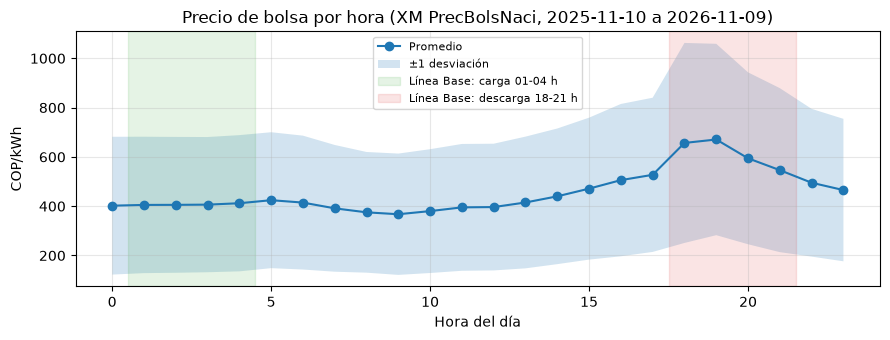

In [3]:
perfil = df_precios.groupby("hora")["precio_cop_kwh"].agg(["mean", "std"])
plt.figure(figsize=(9, 3.5))
plt.plot(perfil.index, perfil["mean"], marker="o", label="Promedio")
plt.fill_between(perfil.index, perfil["mean"] - perfil["std"], perfil["mean"] + perfil["std"],
                 alpha=0.2, label="±1 desviación")
plt.axvspan(0.5, 4.5, color="tab:green", alpha=0.12, label="Línea Base: carga 01-04 h")
plt.axvspan(17.5, 21.5, color="tab:red", alpha=0.12, label="Línea Base: descarga 18-21 h")
plt.title(f"Precio de bolsa por hora ({FUENTE}, {FECHA_INICIO} a {FECHA_FIN})")
plt.xlabel("Hora del día"); plt.ylabel("COP/kWh"); plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 2. División cronológica 70 / 15 / 15 y entornos

- **Entrenamiento:** el agente aprende y se estima el modelo empírico de Iteración de Valores.
- **Validación:** solo para elegir `alpha` y el decaimiento de ε.
- **Prueba:** solo para reportar las métricas finales.

**Cuartiles con ventana móvil causal:** los umbrales (p25, p50, p75) de la hora *t* se calculan con
las 168 horas anteriores (*t*−168 … *t*−1), nunca con la hora actual ni con el futuro. Se calculan una
sola vez sobre la serie completa y se recortan por conjunto, así la primera semana de validación usa
el final de entrenamiento y la de prueba el final de validación (pasado, no futuro). Las primeras 168 h
de la serie usan los cuartiles de esa primera semana de entrenamiento.

Entrenamiento  255 días  2025-11-10 a 2026-07-22
Validación      55 días  2026-07-23 a 2026-09-15
Prueba          55 días  2026-09-16 a 2026-11-09
Umbrales p25/p50/p75 al inicio de entrenamiento: [183.5 273.  282.5]
Umbrales p25/p50/p75 al inicio de prueba:       [425.5 491.7 591.1]
Cuartiles fijos de todo el entrenamiento (antes): [154.4 265.5 432.3]


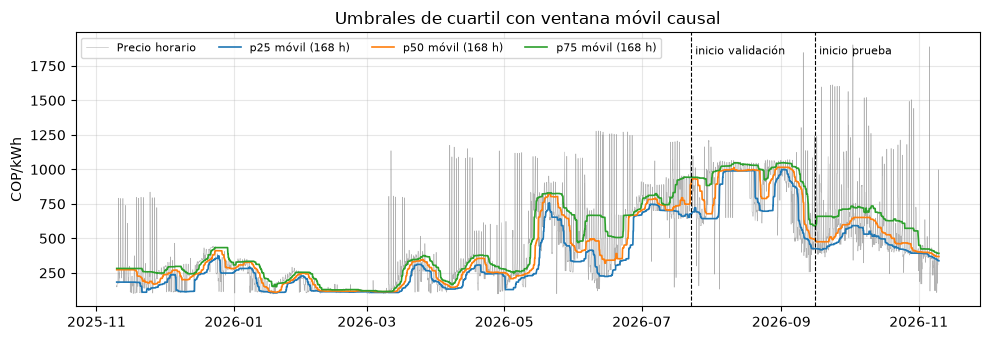

In [4]:
fechas = sorted(df_precios["fecha"].unique())
n = len(fechas)
corte_train, corte_val = int(n * FRACCION_TRAIN), int(n * (FRACCION_TRAIN + FRACCION_VAL))
fechas_train, fechas_val, fechas_test = fechas[:corte_train], fechas[corte_train:corte_val], fechas[corte_val:]

def precios_de(fechas_sub):
    return df_precios[df_precios["fecha"].isin(fechas_sub)]["precio_cop_kwh"].to_numpy()

precios_train, precios_val, precios_test = map(precios_de, (fechas_train, fechas_val, fechas_test))

def crear_env(precios, aleatorio=False, semilla=None, umbrales=None):
    return BatteryEnv(precios, soc_inicial=0, penalizacion_invalida=PENALIZACION,
                      energia_por_nivel_kwh=ENERGIA_POR_NIVEL_KWH, umbrales_precio=umbrales,
                      aleatorio=aleatorio, semilla=semilla)

# Umbrales causales por hora sobre la serie completa (orden cronológico, sin huecos).
serie_completa = df_precios["precio_cop_kwh"].to_numpy()
assert np.array_equal(serie_completa, np.concatenate([precios_train, precios_val, precios_test]))
UMBRALES_HORA = umbrales_moviles(serie_completa, VENTANA_CUARTILES_H)
n_tr, n_va = len(precios_train), len(precios_val)
UMB_TRAIN = UMBRALES_HORA[:n_tr]
UMB_VAL = UMBRALES_HORA[n_tr:n_tr + n_va]
UMB_TEST = UMBRALES_HORA[n_tr + n_va:]
env_val = crear_env(precios_val, umbrales=UMB_VAL)
env_test = crear_env(precios_test, umbrales=UMB_TEST)

for nombre, f in (("Entrenamiento", fechas_train), ("Validación", fechas_val), ("Prueba", fechas_test)):
    print(f"{nombre:<14} {len(f):>3} días  {f[0]} a {f[-1]}")
print("Umbrales p25/p50/p75 al inicio de entrenamiento:", UMB_TRAIN[0].round(1))
print("Umbrales p25/p50/p75 al inicio de prueba:      ", UMB_TEST[0].round(1))
print("Cuartiles fijos de todo el entrenamiento (antes):", np.quantile(precios_train, [.25, .5, .75]).round(1))

umb = pd.DataFrame(UMBRALES_HORA, columns=["p25", "p50", "p75"], index=df_precios["timestamp"])
plt.figure(figsize=(10, 3.5))
plt.plot(df_precios["timestamp"], serie_completa, lw=0.4, color="gray", alpha=0.6, label="Precio horario")
for c in umb.columns:
    plt.plot(umb.index, umb[c], lw=1.2, label=f"{c} móvil (168 h)")
for f, nombre in ((fechas_val[0], "inicio validación"), (fechas_test[0], "inicio prueba")):
    plt.axvline(pd.Timestamp(f), color="k", ls="--", lw=0.8)
    plt.text(pd.Timestamp(f), plt.ylim()[1] * 0.92, f" {nombre}", fontsize=8)
plt.title("Umbrales de cuartil con ventana móvil causal"); plt.ylabel("COP/kWh")
plt.legend(fontsize=8, ncol=4); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [5]:
def evaluar(env: BatteryEnv, selector) -> pd.DataFrame:
    """Ejecuta `selector(estado) -> accion` sobre todos los días del entorno (sin exploración)."""
    filas = []
    for dia in range(env.n_dias):
        estado = env.reset(dia=dia)
        terminado = False
        while not terminado:
            estado, _, terminado, info = env.step(selector(estado))
            filas.append(info)
    df = pd.DataFrame(filas)
    df["accion"] = df["accion"].map(lambda a: Accion(a).name)
    df["ahorro_acumulado_cop"] = df["flujo_caja_cop"].cumsum()
    return df

def ahorro(env, selector) -> float:
    return float(evaluar(env, selector)["flujo_caja_cop"].sum())

def entrenar_agente(alpha, frac_decaimiento, semilla):
    agente = QLearningAgent(n_acciones=BatteryEnv.N_ACCIONES, alpha=alpha, gamma=GAMMA,
                            epsilon_inicial=1.0, epsilon_final=0.05,
                            episodios_decaimiento=int(EPISODIOS * frac_decaimiento), semilla=semilla)
    env_train = crear_env(precios_train, aleatorio=True, semilla=semilla, umbrales=UMB_TRAIN)
    retornos = agente.entrenar(env_train, episodios=EPISODIOS)
    return agente, retornos

greedy = lambda ag: (lambda s: ag.seleccionar_accion(s, explorar=False))

## 3. Selección de hiperparámetros (solo validación)

Rejilla: `alpha` ∈ {0.05, 0.1, 0.3, 0.5, 0.7, 0.9} × fracción de episodios en que ε decae de 1.0 a 0.05
∈ {0.5, 0.8}, con 5 semillas por combinación y 5,000 episodios cada una. Se elige la combinación con
mayor ahorro **medio** en validación. Los días de prueba no intervienen.

In [6]:
ALPHAS = [0.05, 0.1, 0.3, 0.5, 0.7, 0.9]
DECAIMIENTOS = [0.5, 0.8]
SEMILLAS_BUSQUEDA = [0, 1, 2, 3, 4]

t0 = time.time()
filas = []
for alpha in ALPHAS:
    for frac in DECAIMIENTOS:
        for semilla in SEMILLAS_BUSQUEDA:
            ag, _ = entrenar_agente(alpha, frac, semilla)
            filas.append({"alpha": alpha, "decaimiento": frac, "semilla": semilla,
                          "ahorro_val": ahorro(env_val, greedy(ag))})
busqueda = (pd.DataFrame(filas).groupby(["alpha", "decaimiento"])["ahorro_val"]
            .agg(media="mean", desv="std", minimo="min").round(0).sort_values("media", ascending=False))
mejor_alpha, mejor_decaimiento = busqueda.index[0]
print(f"Búsqueda: {len(filas)} entrenamientos en {time.time() - t0:.0f} s")
print(f"Elegido: alpha = {mejor_alpha}, ε decae en el {mejor_decaimiento:.0%} de los episodios")
print(f"Referencia en validación: Línea Base = {ahorro(env_val, BatteryEnv.naive_policy):,.0f} COP")
busqueda

Búsqueda: 60 entrenamientos en 105 s
Elegido: alpha = 0.3, ε decae en el 80% de los episodios
Referencia en validación: Línea Base = 38,598 COP


media     desv   minimo
alpha decaimiento                           
0.30  0.8          23550.0   8511.0  14843.0
      0.5          20414.0   6516.0   9621.0
0.50  0.8          20236.0   9355.0   8218.0
0.90  0.5          19888.0   6537.0  10286.0
0.50  0.5          19542.0   6476.0  11201.0
0.70  0.5          18093.0   8577.0   6851.0
      0.8          15187.0   9578.0   4315.0
0.90  0.8          14526.0  10279.0   2706.0
0.10  0.8          10265.0   4741.0   6201.0
      0.5           9719.0   3257.0   5575.0
0.05  0.8           5691.0    516.0   5028.0
      0.5           2197.0    554.0   1591.0

## 4. Entrenamiento final (5,000 episodios) y política de referencia

El agente final se entrena con los hiperparámetros elegidos y `SEMILLA = 42` (fijada de antemano).
La política de referencia resuelve el mismo MDP con Iteración de Valores sobre las probabilidades de
transición de cuartil y los precios medios estimados con los días de entrenamiento.

Episodios: 5000 | epsilon final: 0.050 | estados visitados: 438 de 480


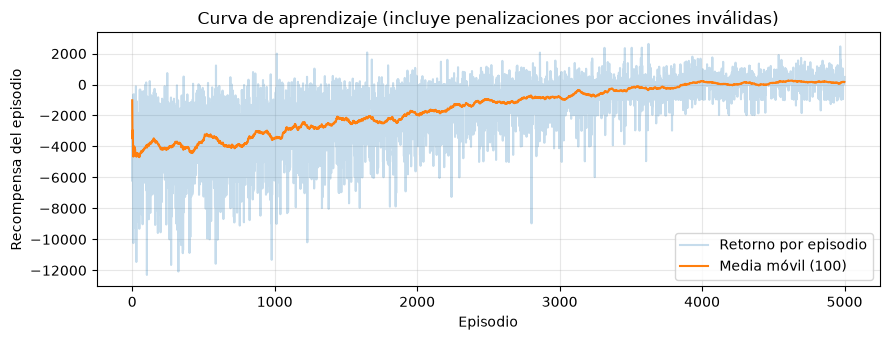

Iteración de Valores: convergió en 25 barridos


In [7]:
agente, retornos = entrenar_agente(mejor_alpha, mejor_decaimiento, SEMILLA)
print(f"Episodios: {len(retornos)} | epsilon final: {agente.epsilon:.3f} | "
      f"estados visitados: {len(agente.q_table)} de {24 * 4 * 5}")

serie = pd.Series(retornos)
plt.figure(figsize=(9, 3.5))
plt.plot(serie, alpha=0.25, label="Retorno por episodio")
plt.plot(serie.rolling(100, min_periods=1).mean(), label="Media móvil (100)")
plt.title("Curva de aprendizaje (incluye penalizaciones por acciones inválidas)")
plt.xlabel("Episodio"); plt.ylabel("Recompensa del episodio")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

referencia = value_iteration_policy(precios_train, UMB_TRAIN, ENERGIA_POR_NIVEL_KWH, GAMMA, PENALIZACION)
print(f"Iteración de Valores: convergió en {referencia.iteraciones} barridos")

In [8]:
# Artefactos para `simular()` y la herramienta `simular_despacho` del agente LLM (Parte 2).
DIR_PROCESADO = RAIZ / "data" / "processed"
ruta_eval = DIR_PROCESADO / "precios_evaluacion.csv"
eval_df = df_precios[df_precios["fecha"].isin(fechas_test)][["timestamp", "precio_cop_kwh"]].copy()
eval_df[["umbral_p25", "umbral_p50", "umbral_p75"]] = UMB_TEST  # umbrales causales de cada hora
eval_df.to_csv(ruta_eval, index=False)
ruta_ref = referencia.guardar(DIR_PROCESADO / "politica_referencia.json",
                              metadatos={"fuente_datos": FUENTE,
                                         "fechas_entrenamiento": [str(fechas_train[0]), str(fechas_train[-1])]})
ruta_q = agente.guardar(
    DIR_PROCESADO / "q_table.json",
    metadatos={
        "fuente_datos": FUENTE,
        "origen_datos": ORIGEN,
        "cuartiles": "ventana movil causal",
        "ventana_cuartiles_h": VENTANA_CUARTILES_H,
        "soc_inicial": 0,
        "penalizacion_invalida": PENALIZACION,
        "energia_por_nivel_kwh_entrenamiento": ENERGIA_POR_NIVEL_KWH,
        "episodios": EPISODIOS,
        "alpha_elegido": mejor_alpha,
        "fraccion_decaimiento_epsilon": mejor_decaimiento,
        "fechas_entrenamiento": [str(fechas_train[0]), str(fechas_train[-1])],
        "fechas_validacion": [str(fechas_val[0]), str(fechas_val[-1])],
        "fechas_evaluacion": [str(fechas_test[0]), str(fechas_test[-1])],
        "archivo_precios_evaluacion": ruta_eval.name,
        "archivo_politica_referencia": ruta_ref.name,
    },
)
print(f"Guardados: {ruta_q.name}, {ruta_ref.name}, {ruta_eval.name}")

Guardados: q_table.json, politica_referencia.json, precios_evaluacion.csv


## 5. Evaluación en prueba: ahorro acumulado (COP)

Cada política recorre todos los días de prueba en orden, sin exploración, con la batería vacía al
inicio de cada día. El ahorro usa el flujo de caja real (`info["flujo_caja_cop"]`), sin la penalización
artificial. Como cota superior (no implementable) se agrega el óptimo con **información perfecta**:
programación dinámica por día conociendo los 24 precios reales de antemano.

In [9]:
def optimo_informacion_perfecta(precios, energia=ENERGIA_POR_NIVEL_KWH) -> float:
    total = 0.0
    for p in np.asarray(precios).reshape(-1, 24):
        V = np.full(5, -np.inf); V[0] = 0.0
        for precio in p:
            nuevo = V.copy()                                           # mantener
            nuevo[1:] = np.maximum(nuevo[1:], V[:-1] - precio * energia)  # cargar
            nuevo[:-1] = np.maximum(nuevo[:-1], V[1:] + precio * energia)  # descargar
            V = nuevo
        total += V.max()
    return total

df_base = evaluar(env_test, BatteryEnv.naive_policy)
df_ql = evaluar(env_test, greedy(agente))
df_ref = evaluar(env_test, referencia.accion)
cota = optimo_informacion_perfecta(precios_test)

def fila(df):
    return {"Ahorro acumulado (COP)": df["flujo_caja_cop"].sum(),
            "Cargas": int(((df["accion"] == "CARGAR") & df["valida"]).sum()),
            "Descargas": int(((df["accion"] == "DESCARGAR") & df["valida"]).sum()),
            "Acciones inválidas": int((~df["valida"]).sum())}

tabla = pd.DataFrame({
    "Línea Base justa (01-04 h / 18-21 h)": fila(df_base),
    f"Q-Learning (α={mejor_alpha}, 5,000 ep.)": fila(df_ql),
    "Iteración de Valores (referencia)": fila(df_ref),
}).T
tabla["% de la cota superior"] = (100 * tabla["Ahorro acumulado (COP)"] / cota).round(1)
tabla["vs. Línea Base"] = (100 * (tabla["Ahorro acumulado (COP)"] / tabla.iloc[0, 0] - 1)).round(1).map("{:+.1f} %".format)
tabla["Ahorro acumulado (COP)"] = tabla["Ahorro acumulado (COP)"].round(0)
print(f"Prueba: {len(fechas_test)} días ({fechas_test[0]} a {fechas_test[-1]}), batería de 4 kWh (1 kWh por escalón)")
print(f"Cota superior con información perfecta: {cota:,.0f} COP")
tabla

Prueba: 55 días (2026-09-16 a 2026-11-09), batería de 4 kWh (1 kWh por escalón)
Cota superior con información perfecta: 109,546 COP


,Ahorro acumulado (COP),Cargas,Descargas,Acciones inválidas,% de la cota superior,vs. Línea Base
Línea Base justa (01-04 h / 18-21 h),89338.0,220.0,220.0,0.0,81.6,+0.0 %
"Q-Learning (α=0.3, 5,000 ep.)",37854.0,152.0,152.0,0.0,34.6,-57.6 %
Iteración de Valores (referencia),95134.0,415.0,415.0,0.0,86.8,+6.5 %


In [10]:
# Robustez: mismo entrenamiento final con 5 semillas distintas, evaluado en prueba.
ahorros_semillas = [ahorro(env_test, greedy(entrenar_agente(mejor_alpha, mejor_decaimiento, s)[0]))
                    for s in (42, 7, 13, 21, 99)]
print("Q-Learning en prueba por semilla:", [f"{a:,.0f}" for a in ahorros_semillas])
print(f"Media {np.mean(ahorros_semillas):,.0f} COP ± {np.std(ahorros_semillas, ddof=1):,.0f}")

Q-Learning en prueba por semilla: ['37,854', '65,440', '34,420', '33,524', '43,482']
Media 42,944 COP ± 13,169


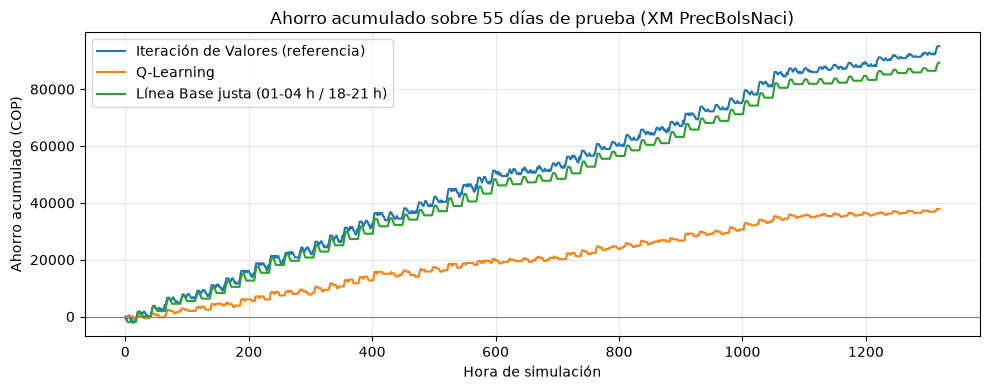

In [11]:
plt.figure(figsize=(10, 4))
plt.plot(df_ref["ahorro_acumulado_cop"].to_numpy(), label="Iteración de Valores (referencia)")
plt.plot(df_ql["ahorro_acumulado_cop"].to_numpy(), label="Q-Learning")
plt.plot(df_base["ahorro_acumulado_cop"].to_numpy(), label="Línea Base justa (01-04 h / 18-21 h)")
plt.axhline(0, color="gray", lw=0.8)
plt.title(f"Ahorro acumulado sobre {env_test.n_dias} días de prueba ({FUENTE})")
plt.xlabel("Hora de simulación"); plt.ylabel("Ahorro acumulado (COP)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [12]:
# Comprobación: simular() (lo que usa el agente LLM) reproduce las cifras del notebook.
from src.part1_rl.simulacion import simular
r = simular(4.0)
print(f"simular(4 kWh): Q-Learning {r.ahorro_qlearning_cop:,.0f} | Línea Base {r.ahorro_base_cop:,.0f} | "
      f"Iteración de Valores {r.ahorro_referencia_cop:,.0f} COP")
assert np.isclose(r.ahorro_qlearning_cop, df_ql["flujo_caja_cop"].sum())
assert np.isclose(r.ahorro_base_cop, df_base["flujo_caja_cop"].sum())
assert np.isclose(r.ahorro_referencia_cop, df_ref["flujo_caja_cop"].sum())
r.traza.head(26)

simular(4 kWh): Q-Learning 37,854 | Línea Base 89,338 | Iteración de Valores 95,134 COP


,timestamp,precio_cop,soc_rl,accion_rl,ahorro_acum_rl,ahorro_acum_base,ahorro_acum_ref
0,2026-09-16 00:00:00,442.35587,25.0,CARGAR,-442.35587,0.00000,-442.35587
1,2026-09-16 01:00:00,442.35587,25.0,MANTENER,-442.35587,-442.35587,-884.71174
2,2026-09-16 02:00:00,442.35587,25.0,MANTENER,-442.35587,-884.71174,-1327.06761
3,2026-09-16 03:00:00,517.81287,0.0,DESCARGAR,75.45700,-1402.52461,-809.25474
4,2026-09-16 04:00:00,554.44087,0.0,MANTENER,75.45700,-1956.96548,-254.81387
5,2026-09-16 05:00:00,660.00787,0.0,MANTENER,75.45700,-1956.96548,405.19400
6,2026-09-16 06:00:00,660.00787,0.0,MANTENER,75.45700,-1956.96548,405.19400
7,2026-09-16 07:00:00,660.00787,0.0,MANTENER,75.45700,-1956.96548,-254.81387
8,2026-09-16 08:00:00,473.25687,0.0,MANTENER,75.45700,-1956.96548,-728.07074
9,2026-09-16 09:00:00,660.00787,0.0,MANTENER,75.45700,-1956.96548,-1388.07861


In [13]:
# Política aprendida vs. referencia: acción greedy por hora y cuartil de precio, con SoC = 50 %.
nombres = {0: "M", 1: "C", 2: "D"}
def tabla_politica(selector, visitado=lambda e: True):
    return pd.DataFrame([[nombres[selector((h, c, 2))] if visitado((h, c, 2)) else "·" for h in range(24)]
                         for c in range(4)], index=[f"Q{c + 1}" for c in range(4)], columns=range(24))
print("M=Mantener, C=Cargar, D=Descargar, ·=estado no visitado (SoC 50 %)")
print("Q-Learning:"); display(tabla_politica(greedy(agente), lambda e: e in agente.q_table))
print("Iteración de Valores:"); display(tabla_politica(referencia.accion))

M=Mantener, C=Cargar, D=Descargar, ·=estado no visitado (SoC 50 %)
Q-Learning:


,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Q1,·,·,M,M,M,D,C,M,M,M,...,M,M,M,D,D,M,D,D,D,D
Q2,·,·,D,M,D,M,D,C,M,D,...,M,M,M,M,M,M,M,D,D,D
Q3,·,·,D,M,D,D,D,M,M,C,...,M,M,D,D,M,D,D,D,D,D
Q4,·,·,D,M,M,M,D,M,D,M,...,M,M,M,M,M,D,M,D,D,D


Iteración de Valores:


,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Q1,C,C,M,C,C,C,C,D,M,C,...,C,C,C,C,C,D,C,D,D,D
Q2,M,C,C,D,D,D,D,M,C,C,...,C,C,C,C,C,C,D,M,D,D
Q3,D,D,M,D,D,D,D,D,D,C,...,C,C,C,C,M,D,D,D,D,D
Q4,D,D,D,M,D,D,D,C,M,C,...,C,C,M,C,D,D,D,D,D,D
